# v2 — Notebook 03 · Behaviour analysis (EU monthly trade)

**Where we are:** data is loaded, validated and feature-rich (notebook 02). Now we *characterise
its behaviour* — the patterns a model must respect — and run the statistical diagnostics that
justify our later modelling choices.

**What this notebook answers**
1. (caveats) Is every country fully covered? Are the newest months provisional?
2. **Trend** — which countries' trade grows fastest?
3. **Seasonality** — STL decomposition; how strong are trend vs season?
4. **Volatility** — rolling statistics; when does trade get turbulent?
5. **Stationarity** — ADF test + ACF/PACF (these tell forecasting models how to be configured).
6. **Normality** — are STL residuals bell-shaped? (justifies the z-score anomaly rule)
7. **Co-movement & lead-lag** — do countries move together, and does anyone move *first*?

Logic lives in `src/analysis.py`; this notebook imports and demonstrates it.
> ⚠️ v2 = international trade.

## Step 0 · Setup

In [1]:
import sys
from pathlib import Path
def find_v2_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "src" / "analysis.py").exists():
            return base
    raise FileNotFoundError("v2 root not found")
V2 = find_v2_root(); sys.path.insert(0, str(V2))
DATA = V2.parent / "data" / "eu_trade_monthly.csv"

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as ss
plt.rcParams["figure.dpi"] = 110
from src import preprocess as pp
from src import analysis as an

df = pp.load_trade(DATA)            # raw flows
logged = pp.log_transform(df)       # log scale (for growth/stationarity)
print("loaded:", df.shape, "| log:", logged.shape)

loaded: (292, 54) | log: (292, 54)


## Step 1 · Data caveats — coverage & provisional months

**What:** confirm every country spans the full 2002–2026 range, and flag that the **most recent
months are provisional** (Eurostat revises them). **Why:** these are honest limitations to state in
the report; the last 1–2 months shouldn't be over-interpreted.
**How to read:** all `n` should equal 292; `first`/`last` identical across countries.

In [2]:
cov = an.coverage(df)
print("Countries with full coverage (n == 292):", int((cov["n"] == 292).sum()), "/", len(cov))
print("All start:", cov["first"].min().date(), "| all end:", cov["last"].max().date())
print("\n!! Caveat: the last 1-2 months (", df.index[-2].date(), ",", df.index[-1].date(),
      ") are PROVISIONAL and may be revised by Eurostat -> don't over-interpret the very end.")
cov.head(3)

Countries with full coverage (n == 292): 27 / 27
All start: 2002-01-01 | all end: 2026-04-01

!! Caveat: the last 1-2 months ( 2026-03-01 , 2026-04-01 ) are PROVISIONAL and may be revised by Eurostat -> don't over-interpret the very end.


,first,last,n
AT,2002-01-01 00:00:00,2026-04-01 00:00:00,292
BE,2002-01-01 00:00:00,2026-04-01 00:00:00,292
BG,2002-01-01 00:00:00,2026-04-01 00:00:00,292


## Step 2 · Trend — who grows fastest?

**What:** the slope of each country's **log** exports = its average **growth rate** per month.
**Why:** trend is the dominant behaviour; on the log scale the slope is comparable across big and
small countries. **How to read:** taller bar = faster-growing exporter.

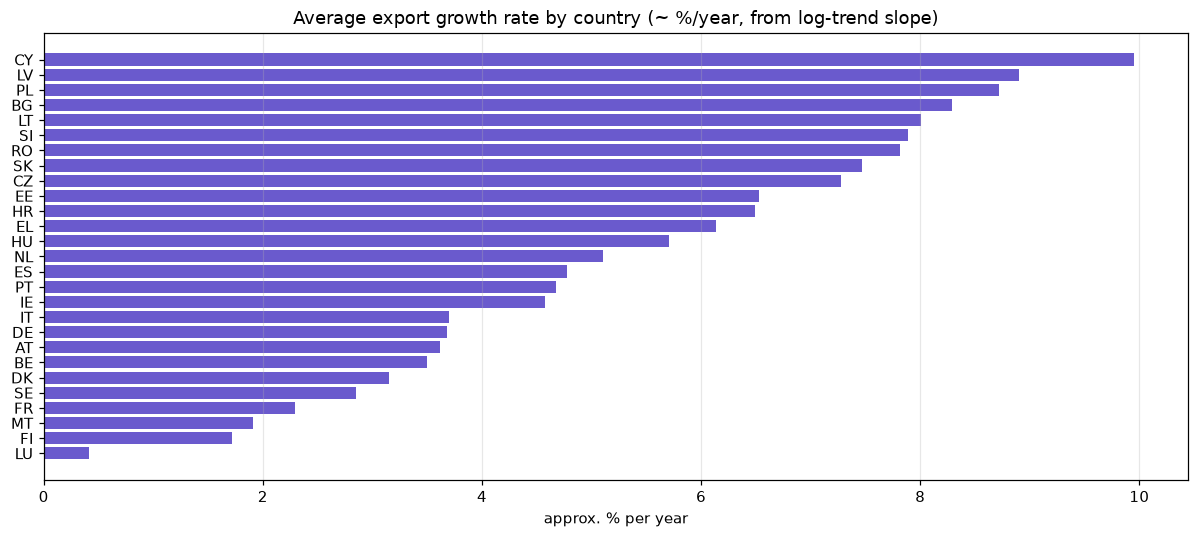

Fastest: {'PL': 8.7, 'LV': 8.9, 'CY': 9.9}
Slowest: {'LU': 0.4, 'FI': 1.7, 'MT': 1.9}


In [3]:
exp_log = [c for c in logged.columns if c.endswith("_EXP")]
slopes = an.trend_slopes(logged, exp_log) * 12 * 100      # monthly log-slope -> ~%/year
slopes.index = [c[:2] for c in slopes.index]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(slopes.index, slopes.values, color="slateblue")
ax.set_title("Average export growth rate by country (~ %/year, from log-trend slope)")
ax.set_xlabel("approx. % per year"); ax.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()
print("Fastest:", slopes.sort_values().tail(3).round(1).to_dict())
print("Slowest:", slopes.sort_values().head(3).round(1).to_dict())

## Step 3 · Seasonality — STL decomposition & strength

**What:** decompose two example countries (France, Belgium) into trend + seasonal + residual, and
measure **trend strength** and **seasonal strength** (0–1). **Why:** confirms how much of each
series is predictable structure vs anomaly-bearing residual. **How to read:** strengths near 1 =
that component dominates; the residual is where anomalies live.

FR_EXP : trend strength=0.93, seasonal strength=0.67
BE_EXP : trend strength=0.96, seasonal strength=0.44


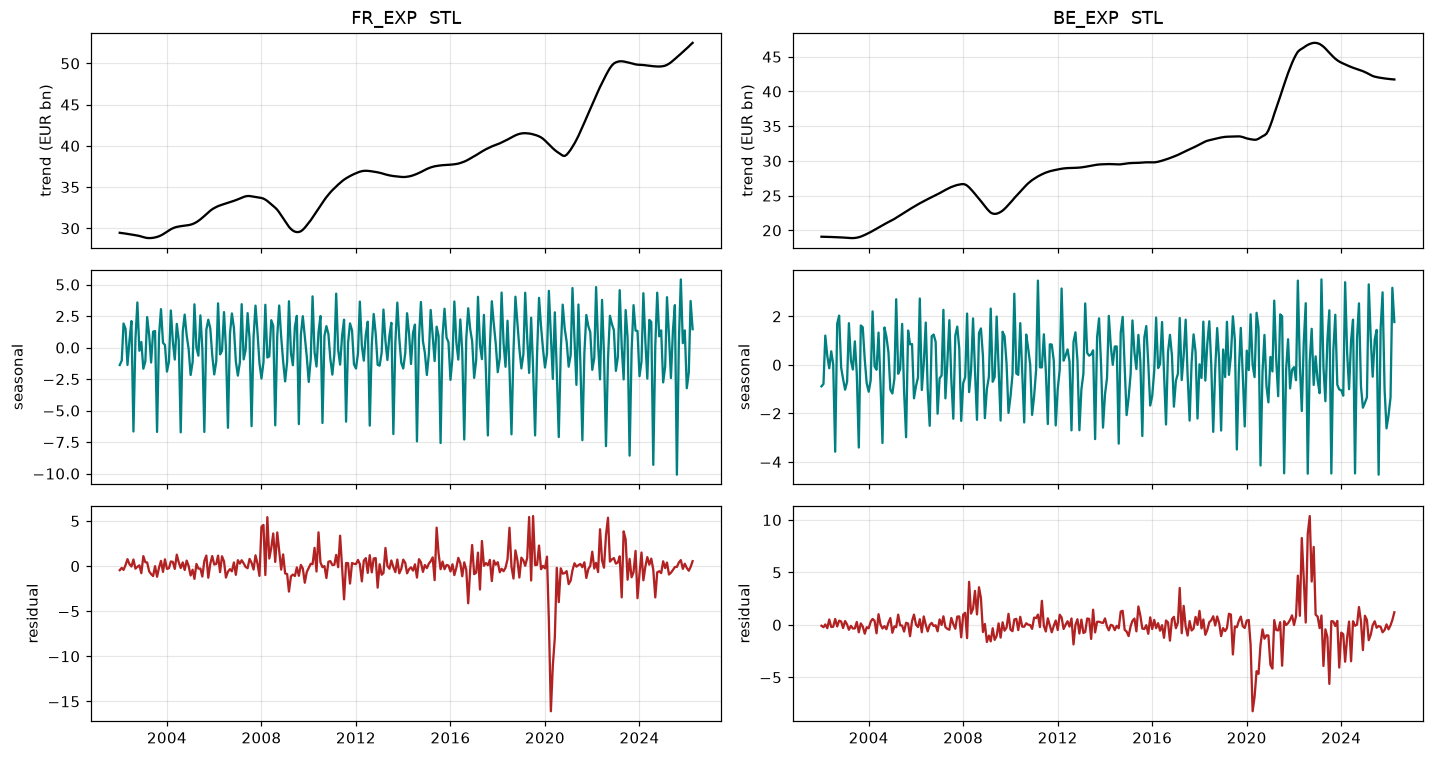

In [4]:
fig, ax = plt.subplots(3, 2, figsize=(13, 7), sharex=True)
for col, cc in enumerate(["FR", "BE"]):
    stl = an.decompose(df[f"{cc}_EXP"], period=12)
    ax[0, col].plot(stl.trend/1000, color="black");    ax[0, col].set_title(f"{cc}_EXP  STL")
    ax[0, col].set_ylabel("trend (EUR bn)")
    ax[1, col].plot(stl.seasonal/1000, color="teal");  ax[1, col].set_ylabel("seasonal")
    ax[2, col].plot(stl.resid/1000, color="firebrick");ax[2, col].set_ylabel("residual")
    print(f"{cc}_EXP : trend strength={an.trend_strength(stl):.2f}, "
          f"seasonal strength={an.seasonal_strength(stl):.2f}")
    for r in range(3): ax[r, col].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Step 4 · Volatility — rolling statistics

**What:** 12-month rolling mean and std of France's exports. **Why:** the rolling **std** is a
volatility gauge — it spikes exactly when behaviour becomes unstable (the crises). **How to read:**
peaks in the lower panel mark turbulent periods.

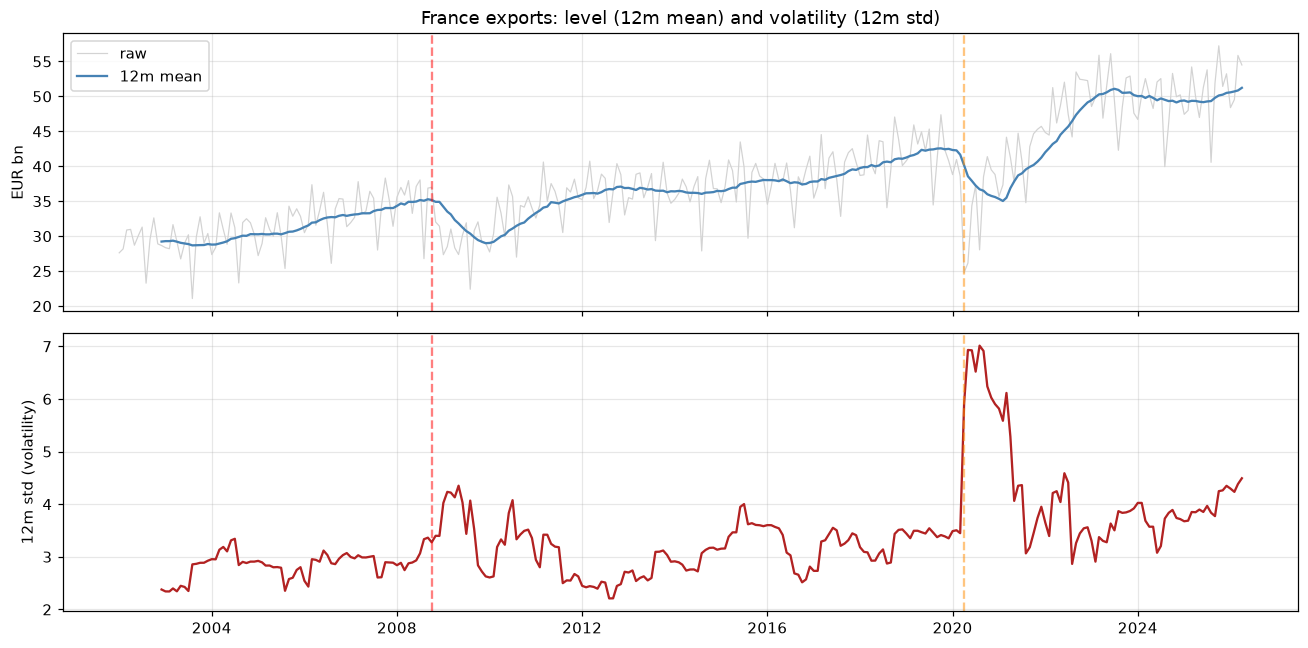

In [5]:
rs = an.rolling_stats(df["FR_EXP"]/1000, window=12)
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(df.index, df["FR_EXP"]/1000, color="lightgrey", lw=.8, label="raw")
ax[0].plot(rs.index, rs["mean"], color="steelblue", label="12m mean"); ax[0].legend(); ax[0].set_ylabel("EUR bn")
ax[1].plot(rs.index, rs["std"], color="firebrick"); ax[1].set_ylabel("12m std (volatility)")
for a in ax:
    for x, c in [("2008-10-01","red"), ("2020-04-01","darkorange")]:
        a.axvline(pd.Timestamp(x), color=c, ls="--", alpha=.5)
    a.grid(alpha=.3)
ax[0].set_title("France exports: level (12m mean) and volatility (12m std)")
plt.tight_layout(); plt.show()

## Step 5 · Stationarity (ADF) + ACF/PACF — *configuring forecasters*

**What:** the **Augmented Dickey-Fuller** test asks "does this series have a trend/unit root?"
We test the log series, then its **12-month seasonal difference**. Then plot **ACF/PACF**.
**Why:** ARIMA-type models need *stationary* input; the tests tell us how much to difference, and
the ACF spike at lag 12 confirms yearly seasonality. **How to read:** p < 0.05 = stationary; a tall
ACF bar at lag 12 = seasonal dependence.

level        : ADF stat=-0.842, p=0.8066 -> NON-stationary (has trend/unit root)
seasonal diff: ADF stat=-4.026, p=0.0013 -> stationary


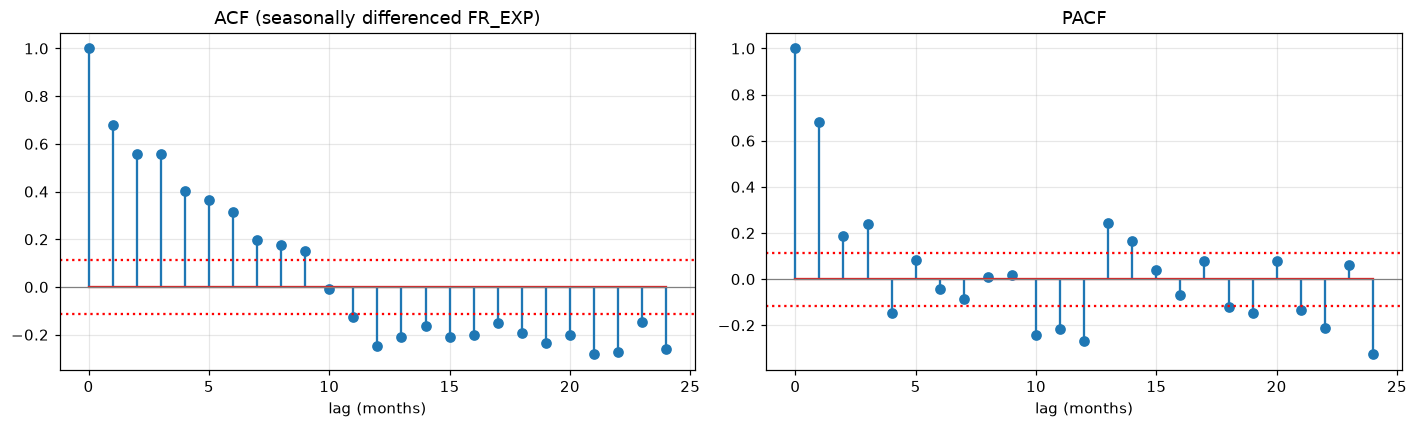

=> level is non-stationary (trend); differencing makes it stationary -> use d/D in ARIMA.


In [6]:
s = logged["FR_EXP"]
print("level        :", an.adf_test(s))
print("seasonal diff:", an.adf_test(s.diff(12)))     # remove yearly seasonality

acf_v, pacf_v = an.acf_pacf(s.diff(12).dropna(), nlags=24)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].stem(range(len(acf_v)), acf_v);  ax[0].set_title("ACF (seasonally differenced FR_EXP)")
ax[1].stem(range(len(pacf_v)), pacf_v);ax[1].set_title("PACF")
for a in ax:
    a.axhline(0, color="grey", lw=.8); a.axhline(1.96/np.sqrt(len(s)), color="red", ls=":")
    a.axhline(-1.96/np.sqrt(len(s)), color="red", ls=":"); a.set_xlabel("lag (months)"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("=> level is non-stationary (trend); differencing makes it stationary -> use d/D in ARIMA.")

## Step 6 · Residual normality — *does the z-score rule hold?*

**What:** a Q-Q plot of the STL residuals against a normal distribution. **Why:** the simplest
anomaly rule (flag |z| > 3) assumes residuals are roughly normal. This checks that assumption.
**How to read:** points on the red line = normal; heavy tails (points curving away at the ends) =
extra extreme events — which is fine, those *are* our anomalies.

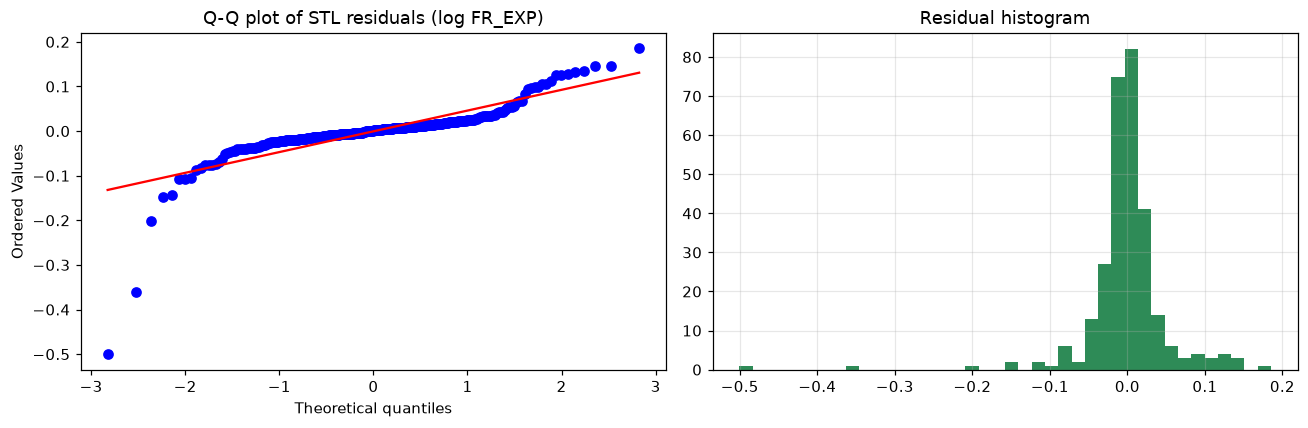

residual skew=-3.18, kurtosis=28.02 (near 0 => roughly normal; fat tails = the crises).


In [7]:
resid = an.decompose(logged["FR_EXP"], period=12).resid.dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ss.probplot(resid, dist="norm", plot=ax[0]); ax[0].set_title("Q-Q plot of STL residuals (log FR_EXP)")
ax[1].hist(resid, bins=40, color="seagreen"); ax[1].set_title("Residual histogram"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"residual skew={ss.skew(resid):.2f}, kurtosis={ss.kurtosis(resid):.2f} "
      f"(near 0 => roughly normal; fat tails = the crises).")

## Step 7 · Co-movement & lead-lag — *the multi-country angle*

**What:** correlation heatmap of export **growth**, the strongest pairs, and a **lead-lag** check
(does one country reliably move a month before another?). **Why:** strong co-movement justifies
multi-country reasoning; lead-lag hints at which economies are bellwethers. **How to read:** greener
heatmap = move together; a non-zero best lag = one country leads.

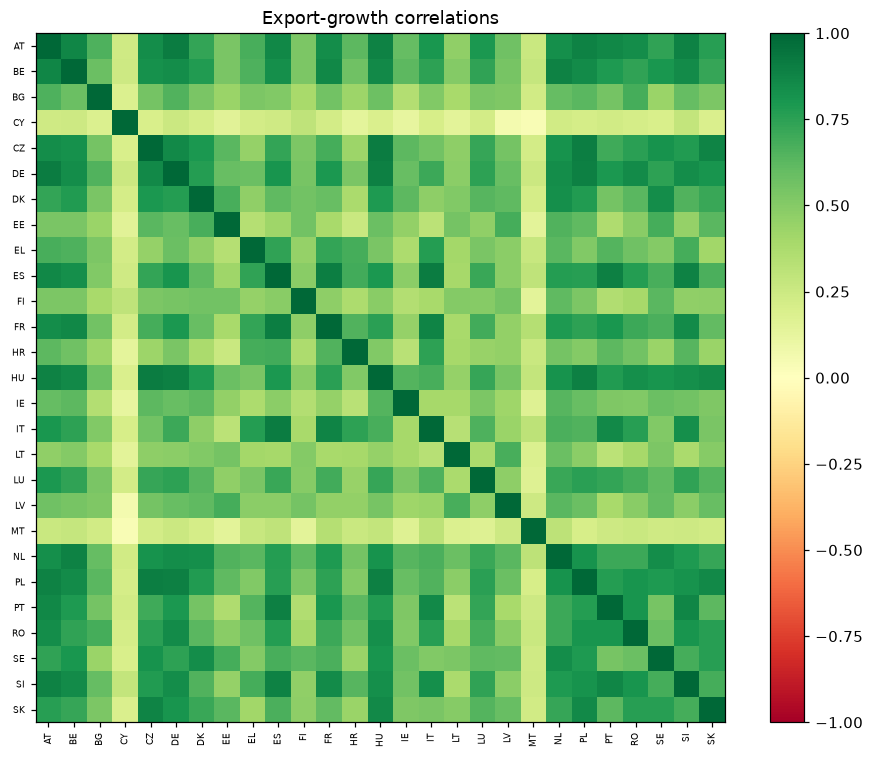

Top co-moving pairs:
ES_EXP  IT_EXP    0.91
AT_EXP  DE_EXP    0.91
CZ_EXP  HU_EXP    0.91
        PL_EXP    0.91
ES_EXP  FR_EXP    0.90

Lead-lag DE vs PL: best lag = 0 month(s), corr = 0.89 (move together).


In [8]:
corr = an.correlations(df, [c for c in df.columns if c.endswith("_EXP")], growth=True)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdYlGn", vmin=-1, vmax=1)
labels = [c[:2] for c in corr.columns]
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90, fontsize=6)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=6)
ax.set_title("Export-growth correlations"); fig.colorbar(im, fraction=.046)
plt.tight_layout(); plt.show()

print("Top co-moving pairs:")
print(an.top_pairs(corr, 5).round(2).to_string())
lag, c = an.lead_lag(df["DE_EXP"], df["PL_EXP"], max_lag=6)
print(f"\nLead-lag DE vs PL: best lag = {lag} month(s), corr = {c:.2f} "
      f"({'DE leads PL' if lag>0 else 'PL leads DE' if lag<0 else 'move together'}).")

## Step 8 · Summary — what behaviour analysis tells the next steps

| Finding | Consequence for modelling |
| --- | --- |
| Strong upward log-trend, varying growth rates | detrend / difference before forecasting; per-country baselines |
| High trend & seasonal strength (STL) | model seasonality (period 12); anomalies live in the **residual** |
| Volatility spikes at the crises | rolling std is itself a useful anomaly signal |
| Level non-stationary, diff is stationary | ARIMA needs differencing (d≥1, seasonal D≥1) |
| Residuals ~normal with fat tails | the **z-score (|z|>3)** rule is reasonable; tails = the real anomalies |
| Countries co-move (and some lead) | **multi-country reasoning** is well-founded |

**→ Next: Notebook 04 · Anomaly detection** — z-score on STL residuals, Isolation Forest, and a deep
model, evaluated against the real 2008 & COVID events.